## Import Libraries

In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

## Configuration
Change only this cell when reusing the notebook for another pose.

In [2]:
POSE_NAME = "Trikonasana"
MODEL_FILENAME = "trikonasana_rf.pkl"

FEATURES = [
    "left_knee",
    "right_knee",
    "left_hip",
    "right_hip",
    "left_shoulder",
    "right_shoulder"
]

TARGET_COL = "target"
RANDOM_STATE = 42

## Fix Data Leakage - Rebuild Train/Val/Test Split
Trikonasana's original split had overlapping rows between train/val/test (near-duplicate frames scattered across splits). This cell deduplicates the raw pose data and rebuilds a clean, leakage-free 70/15/15 split before anything else runs.

**Run this cell once.** It overwrites `train/`, `val/`, `test/` CSVs with a corrected split. Requires the original un-split files `correct_Trikonasana.csv` and `incorrect_Trikonasana.csv` to be present in the working directory (adjust filenames below if yours differ).

In [3]:
import os
from sklearn.model_selection import train_test_split

RAW_CORRECT_FILE = "../CSV/correct_Trikonasana (1).csv"
RAW_INCORRECT_FILE = "../CSV/incorrect_Trikonasana (1).csv"

_features_for_dedup = [
    "left_knee", "right_knee", "left_hip",
    "right_hip", "left_shoulder", "right_shoulder"
]

raw_correct = pd.read_csv(RAW_CORRECT_FILE)
raw_incorrect = pd.read_csv(RAW_INCORRECT_FILE)

print("Before dedup -> Correct:", raw_correct.shape, "| Incorrect:", raw_incorrect.shape)

raw_correct = raw_correct.drop_duplicates(subset=_features_for_dedup).reset_index(drop=True)
raw_incorrect = raw_incorrect.drop_duplicates(subset=_features_for_dedup).reset_index(drop=True)

print("After dedup  -> Correct:", raw_correct.shape, "| Incorrect:", raw_incorrect.shape)

def split_70_15_15(df, random_state=42):
    train, temp = train_test_split(df, test_size=0.30, random_state=random_state)
    val, test = train_test_split(temp, test_size=0.50, random_state=random_state)
    return train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)

correct_train, correct_val, correct_test = split_70_15_15(raw_correct)
incorrect_train, incorrect_val, incorrect_test = split_70_15_15(raw_incorrect)

for split in ["train", "val", "test"]:
    os.makedirs(split, exist_ok=True)

correct_train.to_csv("train/correct_train.csv", index=False)
incorrect_train.to_csv("train/incorrect_train.csv", index=False)
correct_val.to_csv("val/correct_val.csv", index=False)
incorrect_val.to_csv("val/incorrect_val.csv", index=False)
correct_test.to_csv("test/correct_test.csv", index=False)
incorrect_test.to_csv("test/incorrect_test.csv", index=False)

print("\nNew split sizes:")
print("Train:", len(correct_train) + len(incorrect_train))
print("Val  :", len(correct_val) + len(incorrect_val))
print("Test :", len(correct_test) + len(incorrect_test))
print("\nClean split written to train/, val/, test/ folders.")

Before dedup -> Correct: (1380, 11) | Incorrect: (2208, 11)
After dedup  -> Correct: (1050, 11) | Incorrect: (1827, 11)

New split sizes:
Train: 2013
Val  : 431
Test : 433

Clean split written to train/, val/, test/ folders.


## Verify Leakage Is Fixed
Must print 0 / 0 / 0 before continuing to model training below.

In [4]:
_verify_train = pd.concat([
    pd.read_csv("train/correct_train.csv"),
    pd.read_csv("train/incorrect_train.csv")
], ignore_index=True)
_verify_val = pd.concat([
    pd.read_csv("val/correct_val.csv"),
    pd.read_csv("val/incorrect_val.csv")
], ignore_index=True)
_verify_test = pd.concat([
    pd.read_csv("test/correct_test.csv"),
    pd.read_csv("test/incorrect_test.csv")
], ignore_index=True)

_train_set = set(map(tuple, _verify_train[_features_for_dedup].round(4).values))
_val_set   = set(map(tuple, _verify_val[_features_for_dedup].round(4).values))
_test_set  = set(map(tuple, _verify_test[_features_for_dedup].round(4).values))

overlap_train_val  = len(_train_set & _val_set)
overlap_train_test = len(_train_set & _test_set)
overlap_val_test   = len(_val_set & _test_set)

print("Train ∩ Val overlap :", overlap_train_val)
print("Train ∩ Test overlap:", overlap_train_test)
print("Val ∩ Test overlap  :", overlap_val_test)

assert overlap_train_val == 0, "Leakage still present between train and val!"
assert overlap_train_test == 0, "Leakage still present between train and test!"
assert overlap_val_test == 0, "Leakage still present between val and test!"
print("\nNo leakage detected. Safe to proceed with training below.")

Train ∩ Val overlap : 0
Train ∩ Test overlap: 0
Val ∩ Test overlap  : 0

No leakage detected. Safe to proceed with training below.


## Load and Merge Datasets (Train / Val / Test)
Loads the pre-split correct/incorrect CSVs, merges them, and shuffles rows.

In [5]:
def load_and_merge(split_name):
    correct_path = f"{split_name}/correct_{split_name}.csv"
    incorrect_path = f"{split_name}/incorrect_{split_name}.csv"

    if not os.path.exists(correct_path) or not os.path.exists(incorrect_path):
        raise FileNotFoundError(
            f"Missing files for split '{split_name}'. "
            f"Expected: {correct_path} and {incorrect_path}"
        )

    correct_df = pd.read_csv(correct_path)
    incorrect_df = pd.read_csv(incorrect_path)

    df = pd.concat([correct_df, incorrect_df], ignore_index=True)
    df = df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

    return df

train_df = load_and_merge("train")
val_df   = load_and_merge("val")
test_df  = load_and_merge("test")

print("Train Shape :", train_df.shape)
print("Val Shape   :", val_df.shape)
print("Test Shape  :", test_df.shape)

Train Shape : (2013, 11)
Val Shape   : (431, 11)
Test Shape  : (433, 11)


## Sanity Checks

In [6]:
for name, df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    missing = df[FEATURES + [TARGET_COL]].isnull().sum().sum()
    print(f"{name} missing values: {missing}")
    assert missing == 0, f"{name} split has missing values in required columns"

print("\nClass Distribution")
print("Train:\n", train_df[TARGET_COL].value_counts())
print("\nVal:\n", val_df[TARGET_COL].value_counts())
print("\nTest:\n", test_df[TARGET_COL].value_counts())

Train missing values: 0
Val missing values: 0
Test missing values: 0

Class Distribution
Train:
 target
0    1278
1     735
Name: count, dtype: int64

Val:
 target
0    274
1    157
Name: count, dtype: int64

Test:
 target
0    275
1    158
Name: count, dtype: int64


## Feature / Target Split

In [7]:
X_train, y_train = train_df[FEATURES], train_df[TARGET_COL]
X_val,   y_val   = val_df[FEATURES],   val_df[TARGET_COL]
X_test,  y_test  = test_df[FEATURES],  test_df[TARGET_COL]

## Train Random Forest

In [8]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    class_weight="balanced"
)

rf.fit(X_train, y_train)
print("Model Trained Successfully")

Model Trained Successfully


## Train vs Validation Accuracy (Overfitting Check)

In [9]:
train_pred = rf.predict(X_train)
val_pred   = rf.predict(X_val)

train_accuracy = accuracy_score(y_train, train_pred)
val_accuracy   = accuracy_score(y_val, val_pred)

print(f"Train Accuracy      : {train_accuracy*100:.2f}%")
print(f"Validation Accuracy : {val_accuracy*100:.2f}%")
print(f"Gap (Train - Val)   : {(train_accuracy - val_accuracy)*100:.2f}%")

if (train_accuracy - val_accuracy) > 0.10:
    print("Warning: large train-val gap, model may be overfitting")

print("\nValidation Classification Report")
print(classification_report(y_val, val_pred, target_names=["Incorrect", "Correct"]))

Train Accuracy      : 100.00%
Validation Accuracy : 99.77%
Gap (Train - Val)   : 0.23%

Validation Classification Report
              precision    recall  f1-score   support

   Incorrect       1.00      1.00      1.00       274
     Correct       1.00      0.99      1.00       157

    accuracy                           1.00       431
   macro avg       1.00      1.00      1.00       431
weighted avg       1.00      1.00      1.00       431



## Test Set Evaluation

In [10]:
test_pred = rf.predict(X_test)

test_accuracy  = accuracy_score(y_test, test_pred)
test_precision = precision_score(y_test, test_pred)
test_recall    = recall_score(y_test, test_pred)
test_f1        = f1_score(y_test, test_pred)

print(f"Test Accuracy  : {test_accuracy*100:.2f}%")
print(f"Test Precision : {test_precision*100:.2f}%")
print(f"Test Recall    : {test_recall*100:.2f}%")
print(f"Test F1 Score  : {test_f1*100:.2f}%")

print("\nFull Classification Report (Test)")
print(classification_report(y_test, test_pred, target_names=["Incorrect", "Correct"]))

Test Accuracy  : 99.08%
Test Precision : 100.00%
Test Recall    : 97.47%
Test F1 Score  : 98.72%

Full Classification Report (Test)
              precision    recall  f1-score   support

   Incorrect       0.99      1.00      0.99       275
     Correct       1.00      0.97      0.99       158

    accuracy                           0.99       433
   macro avg       0.99      0.99      0.99       433
weighted avg       0.99      0.99      0.99       433



Average confidence : 98.43%
Minimum confidence : 53.00%


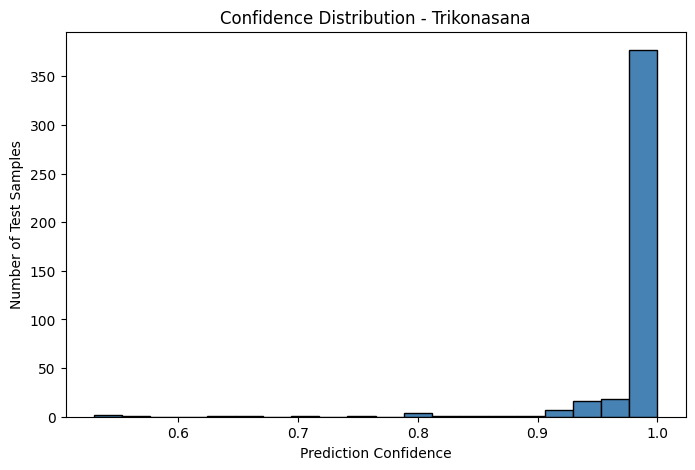

In [11]:
test_probs = rf.predict_proba(X_test)
test_confidence = test_probs.max(axis=1)  # confidence in whichever class was predicted

print(f"Average confidence : {test_confidence.mean()*100:.2f}%")
print(f"Minimum confidence : {test_confidence.min()*100:.2f}%")

plt.figure(figsize=(8, 5))
plt.hist(test_confidence, bins=20, color="steelblue", edgecolor="black")
plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Test Samples")
plt.title(f"Confidence Distribution - {POSE_NAME}")
plt.savefig(f"confidence_distribution_{POSE_NAME.lower().replace(' ', '_')}.png", dpi=150)
plt.show()

## Confusion Matrix

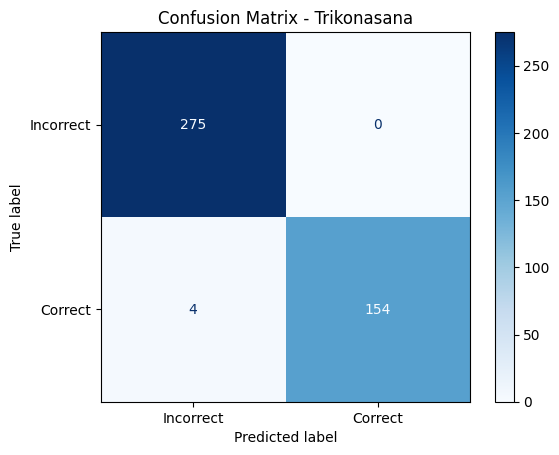

In [12]:
cm = confusion_matrix(y_test, test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Incorrect", "Correct"]
)

disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix - {POSE_NAME}")
plt.savefig(f"confusion_matrix_{POSE_NAME.lower().replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
plt.show()

## Feature Importance

          Feature  Importance
0       right_hip    0.371302
1        left_hip    0.287551
2   left_shoulder    0.189149
3  right_shoulder    0.105885
4       left_knee    0.029388
5      right_knee    0.016725


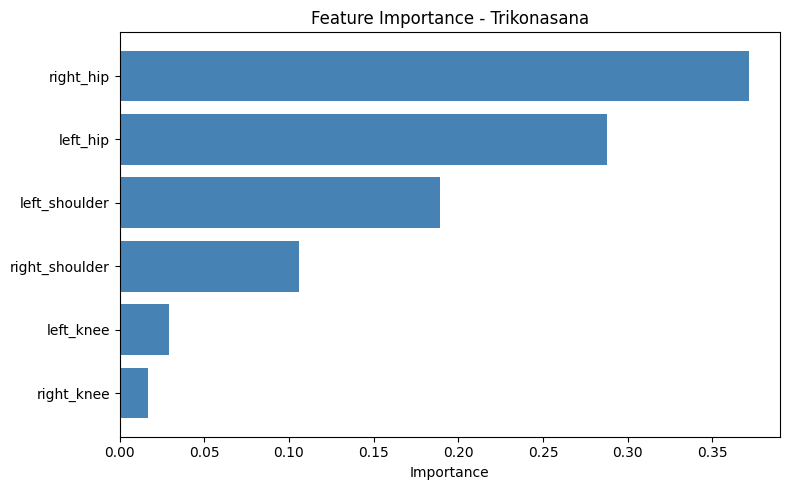

In [13]:
importance_df = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": rf.feature_importances_
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

print(importance_df)

plt.figure(figsize=(8, 5))
plt.barh(importance_df["Feature"], importance_df["Importance"], color="steelblue")
plt.xlabel("Importance")
plt.title(f"Feature Importance - {POSE_NAME}")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(f"feature_importance_{POSE_NAME.lower().replace(' ', '_')}.png", dpi=150)
plt.show()

## Save Model and Metadata

In [14]:
joblib.dump(rf, MODEL_FILENAME)

metadata = {
    "pose_name": POSE_NAME,
    "features": FEATURES,
    "target_mapping": {"0": "Incorrect", "1": "Correct"},
    "train_accuracy": round(train_accuracy, 4),
    "val_accuracy": round(val_accuracy, 4),
    "test_accuracy": round(test_accuracy, 4),
    "test_precision": round(test_precision, 4),
    "test_recall": round(test_recall, 4),
    "test_f1_score": round(test_f1, 4),
    "n_estimators": rf.n_estimators,
    "random_state": rf.random_state
}

metadata_filename = MODEL_FILENAME.replace(".pkl", "_metadata.json")
with open(metadata_filename, "w") as f:
    json.dump(metadata, f, indent=4)

print(f"Model saved as {MODEL_FILENAME}")
print(f"Metadata saved as {metadata_filename}")

Model saved as trikonasana_rf.pkl
Metadata saved as trikonasana_rf_metadata.json


## Test with One Sample

In [15]:
sample = X_test.iloc[[0]]

prediction = rf.predict(sample)[0]
probabilities = rf.predict_proba(sample)[0]
confidence = probabilities[prediction]

print("Prediction :", prediction)
print(f"{'Correct' if prediction == 1 else 'Incorrect'} {POSE_NAME}")
print(f"Confidence : {confidence*100:.2f}%")
print(f"  P(Incorrect) = {probabilities[0]*100:.2f}%")
print(f"  P(Correct)   = {probabilities[1]*100:.2f}%")

Prediction : 0
Incorrect Trikonasana
Confidence : 100.00%
  P(Incorrect) = 100.00%
  P(Correct)   = 0.00%


## Mirror Augmentation Fix - Directional Bend Bias

Real-time testing revealed the model above only recognizes one Trikonasana bend direction as Correct. Checking the raw training data confirmed why: 98.6% of "Correct" examples bend the same direction (`left_hip > right_hip`), so the model never learned the mirrored direction as valid.

**Fix:** for every row, generate a mirrored copy by swapping `left_* <-> right_*` feature values, then retrain on the combined (original + mirrored) data. This teaches both bend directions using data already collected - no new video needed.

**This section retrains and overwrites `trikonasana_rf.pkl` / `trikonasana_rf_metadata.json` with the corrected, direction-balanced model. The evaluation above (pre-mirror) is kept for comparison; the results in this section reflect the final saved model.**

In [16]:
def mirror_dataframe(df):
    """Returns a mirrored copy: left_* and right_* feature values are swapped."""
    mirrored = df.copy()
    mirrored["left_knee"], mirrored["right_knee"] = df["right_knee"], df["left_knee"]
    mirrored["left_hip"], mirrored["right_hip"] = df["right_hip"], df["left_hip"]
    mirrored["left_shoulder"], mirrored["right_shoulder"] = df["right_shoulder"], df["left_shoulder"]
    return mirrored

def load_merge_and_augment(split_name):
    correct_path = f"{split_name}/correct_{split_name}.csv"
    incorrect_path = f"{split_name}/incorrect_{split_name}.csv"

    correct_df = pd.read_csv(correct_path)
    incorrect_df = pd.read_csv(incorrect_path)

    df = pd.concat([correct_df, incorrect_df], ignore_index=True)

    mirrored_df = mirror_dataframe(df)
    augmented_df = pd.concat([df, mirrored_df], ignore_index=True)
    augmented_df = augmented_df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
    return augmented_df

train_df_aug = load_merge_and_augment("train")
val_df_aug   = load_merge_and_augment("val")
test_df_aug  = load_merge_and_augment("test")

print("Post-augmentation shapes (original + mirrored):")
print("Train:", train_df_aug.shape)
print("Val  :", val_df_aug.shape)
print("Test :", test_df_aug.shape)

Post-augmentation shapes (original + mirrored):
Train: (4026, 11)
Val  : (862, 11)
Test : (866, 11)


### Verify Augmentation Introduced No Leakage

In [17]:
_train_set_aug = set(map(tuple, train_df_aug[FEATURES].round(4).values))
_val_set_aug   = set(map(tuple, val_df_aug[FEATURES].round(4).values))
_test_set_aug  = set(map(tuple, test_df_aug[FEATURES].round(4).values))

overlap_train_val_aug  = len(_train_set_aug & _val_set_aug)
overlap_train_test_aug = len(_train_set_aug & _test_set_aug)
overlap_val_test_aug   = len(_val_set_aug & _test_set_aug)

print("Train ∩ Val overlap :", overlap_train_val_aug)
print("Train ∩ Test overlap:", overlap_train_test_aug)
print("Val ∩ Test overlap  :", overlap_val_test_aug)

assert overlap_train_val_aug == 0, "Augmentation introduced leakage between train and val!"
assert overlap_train_test_aug == 0, "Augmentation introduced leakage between train and test!"
assert overlap_val_test_aug == 0, "Augmentation introduced leakage between val and test!"
print("No leakage introduced by mirroring. Safe to train.")

Train ∩ Val overlap : 0
Train ∩ Test overlap: 0
Val ∩ Test overlap  : 0
No leakage introduced by mirroring. Safe to train.


### Retrain on Mirror-Augmented Data

In [18]:
X_train_aug, y_train_aug = train_df_aug[FEATURES], train_df_aug[TARGET_COL]
X_val_aug,   y_val_aug   = val_df_aug[FEATURES],   val_df_aug[TARGET_COL]
X_test_aug,  y_test_aug  = test_df_aug[FEATURES],  test_df_aug[TARGET_COL]

rf_mirror = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    class_weight="balanced"
)
rf_mirror.fit(X_train_aug, y_train_aug)
print("Model trained on mirror-augmented data.")

Model trained on mirror-augmented data.


### Evaluate Mirror-Augmented Model

In [19]:
train_pred_aug = rf_mirror.predict(X_train_aug)
val_pred_aug   = rf_mirror.predict(X_val_aug)
test_pred_aug  = rf_mirror.predict(X_test_aug)

train_accuracy_aug = accuracy_score(y_train_aug, train_pred_aug)
val_accuracy_aug   = accuracy_score(y_val_aug, val_pred_aug)
test_accuracy_aug  = accuracy_score(y_test_aug, test_pred_aug)
test_precision_aug = precision_score(y_test_aug, test_pred_aug)
test_recall_aug    = recall_score(y_test_aug, test_pred_aug)
test_f1_aug        = f1_score(y_test_aug, test_pred_aug)

print(f"Train Accuracy      : {train_accuracy_aug*100:.2f}%")
print(f"Validation Accuracy : {val_accuracy_aug*100:.2f}%")
print(f"Test Accuracy       : {test_accuracy_aug*100:.2f}%")
print(f"Test Precision      : {test_precision_aug*100:.2f}%")
print(f"Test Recall         : {test_recall_aug*100:.2f}%")
print(f"Test F1             : {test_f1_aug*100:.2f}%")

print("\nFull Classification Report (Test)")
print(classification_report(y_test_aug, test_pred_aug, target_names=["Incorrect", "Correct"]))

Train Accuracy      : 100.00%
Validation Accuracy : 93.85%
Test Accuracy       : 93.53%
Test Precision      : 94.22%
Test Recall         : 87.66%
Test F1             : 90.82%

Full Classification Report (Test)
              precision    recall  f1-score   support

   Incorrect       0.93      0.97      0.95       550
     Correct       0.94      0.88      0.91       316

    accuracy                           0.94       866
   macro avg       0.94      0.92      0.93       866
weighted avg       0.94      0.94      0.93       866



### Directional Sanity Check
Confirms both bend directions are now handled comparably (previously one direction had far lower accuracy).

In [20]:
test_df_check = test_df_aug.copy()
test_df_check["pred"] = test_pred_aug

left_bend = test_df_check[test_df_check["left_hip"] > test_df_check["right_hip"]]
right_bend = test_df_check[test_df_check["right_hip"] > test_df_check["left_hip"]]

left_acc = accuracy_score(left_bend[TARGET_COL], left_bend["pred"]) if len(left_bend) > 0 else float("nan")
right_acc = accuracy_score(right_bend[TARGET_COL], right_bend["pred"]) if len(right_bend) > 0 else float("nan")

print(f"Left-bend-dominant rows  (n={len(left_bend)}): accuracy = {left_acc*100:.2f}%")
print(f"Right-bend-dominant rows (n={len(right_bend)}): accuracy = {right_acc*100:.2f}%")

if abs(left_acc - right_acc) > 0.05:
    print("Warning: notable accuracy gap remains between directions.")
else:
    print("Balanced performance across both bend directions.")

Left-bend-dominant rows  (n=433): accuracy = 93.76%
Right-bend-dominant rows (n=433): accuracy = 93.30%
Balanced performance across both bend directions.


### Confusion Matrix (Mirror-Augmented Model)

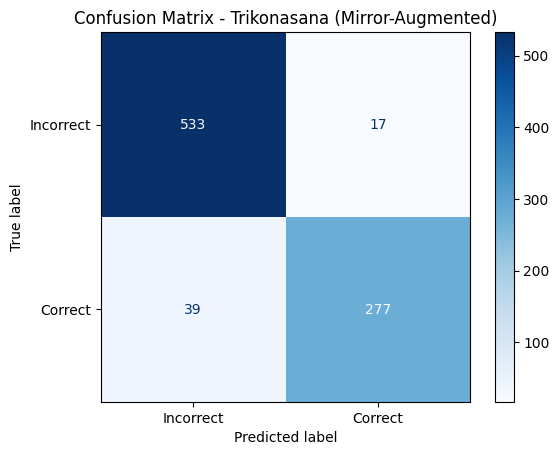

In [21]:
cm_aug = confusion_matrix(y_test_aug, test_pred_aug)

disp_aug = ConfusionMatrixDisplay(
    confusion_matrix=cm_aug,
    display_labels=["Incorrect", "Correct"]
)

disp_aug.plot(cmap="Blues")
plt.title(f"Confusion Matrix - {POSE_NAME} (Mirror-Augmented)")
plt.savefig(f"confusion_matrix_{POSE_NAME.lower()}_mirror_augmented.png", dpi=150, bbox_inches="tight")
plt.show()

### Feature Importance (Mirror-Augmented Model)
Left/right hip and shoulder importance should now be close to balanced (previously skewed toward one side).

          Feature  Importance
0        left_hip    0.218937
1       right_hip    0.215179
2  right_shoulder    0.187109
3   left_shoulder    0.184488
4       left_knee    0.097366
5      right_knee    0.096921


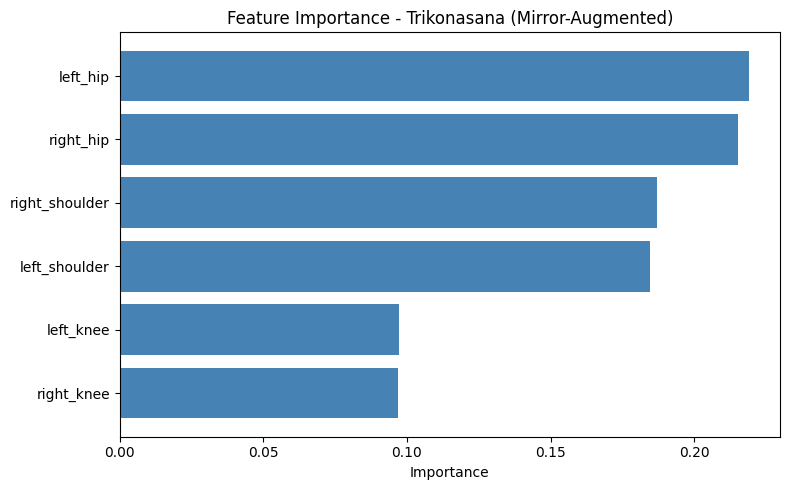

In [22]:
importance_df_aug = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": rf_mirror.feature_importances_
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

print(importance_df_aug)

plt.figure(figsize=(8, 5))
plt.barh(importance_df_aug["Feature"], importance_df_aug["Importance"], color="steelblue")
plt.xlabel("Importance")
plt.title(f"Feature Importance - {POSE_NAME} (Mirror-Augmented)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(f"feature_importance_{POSE_NAME.lower()}_mirror_augmented.png", dpi=150)
plt.show()

### Confidence (Mirror-Augmented Model)

Average confidence : 88.05%
Minimum confidence : 51.00%


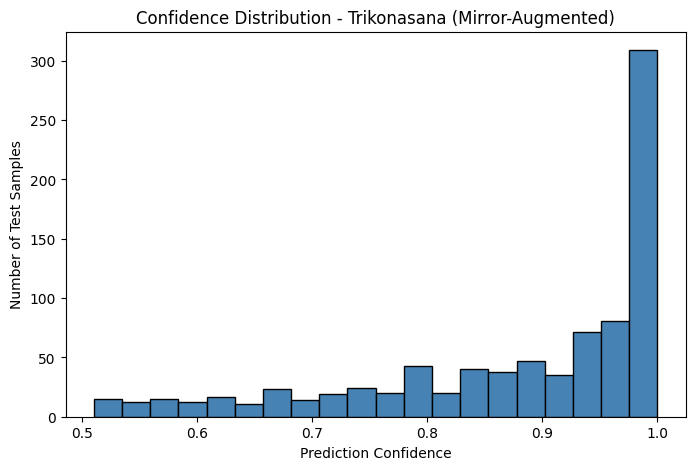

In [23]:
test_probs_aug = rf_mirror.predict_proba(X_test_aug)
test_confidence_aug = test_probs_aug.max(axis=1)

print(f"Average confidence : {test_confidence_aug.mean()*100:.2f}%")
print(f"Minimum confidence : {test_confidence_aug.min()*100:.2f}%")

plt.figure(figsize=(8, 5))
plt.hist(test_confidence_aug, bins=20, color="steelblue", edgecolor="black")
plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Test Samples")
plt.title(f"Confidence Distribution - {POSE_NAME} (Mirror-Augmented)")
plt.savefig(f"confidence_distribution_{POSE_NAME.lower()}_mirror_augmented.png", dpi=150)
plt.show()

### Save Final Model and Metadata
**This overwrites `trikonasana_rf.pkl` / `trikonasana_rf_metadata.json` with the mirror-augmented model. This is the final Trikonasana model going forward.**

In [24]:
joblib.dump(rf_mirror, MODEL_FILENAME)

metadata_aug = {
    "pose_name": POSE_NAME,
    "features": FEATURES,
    "target_mapping": {"0": "Incorrect", "1": "Correct"},
    "train_accuracy": round(train_accuracy_aug, 4),
    "val_accuracy": round(val_accuracy_aug, 4),
    "test_accuracy": round(test_accuracy_aug, 4),
    "test_precision": round(test_precision_aug, 4),
    "test_recall": round(test_recall_aug, 4),
    "test_f1_score": round(test_f1_aug, 4),
    "n_estimators": rf_mirror.n_estimators,
    "random_state": rf_mirror.random_state,
    "mirror_augmented": True,
    "note": "Trained on original + left-right mirrored data to fix directional bend imbalance found in raw dataset (98.6% single-direction in original correct-class data)."
}

metadata_filename = MODEL_FILENAME.replace(".pkl", "_metadata.json")
with open(metadata_filename, "w") as f:
    json.dump(metadata_aug, f, indent=4)

print(f"Model saved as {MODEL_FILENAME}")
print(f"Metadata saved as {metadata_filename}")
print("This is the final Trikonasana model - handles both bend directions.")

Model saved as trikonasana_rf.pkl
Metadata saved as trikonasana_rf_metadata.json
This is the final Trikonasana model - handles both bend directions.
